# Radiometry and photometry: watts, lumens and the radiance that optics cannot raise

How bright is a lamp, a screen or the Sun? The question has several
answers, and they are different quantities with different units: the total
power, the power per direction, the power per area of a lit surface, and
the brightness of the source as an eye sees it. Radiometry gives each of
them a name and a unit, and photometry weights them with the sensitivity
of the eye, which turns watts into lumens. The other illumination
notebooks use these quantities (notebook 83 (étendue) the conservation of radiance,
notebook 88 (LED optics) lux and candela) without introducing them. This notebook does.

The sections are:

1. solid angle, projected area and the four quantities (flux, intensity,
   irradiance and radiance), checked on a Lambertian disk with Monte
   Carlo rays,
2. radiance along a ray and across an interface: why a wall looks equally
   bright from any distance, and why the radiance in glass is $n^2$ times
   that in air,
3. black bodies: Planck's law in absolute units, and the solar constant
   from the temperature of the Sun,
4. photometry: $V(\lambda)$, 683 lm/W, the luminous efficacy of lamps,
   LEDs and lasers, and the shift of colours at dusk,
5. Lambertian surfaces exchanging light: view factors, the integrating
   sphere, and why the full Moon looks like a flat disk,
6. photon quantities, for detectors and plants.

The functions are in `pyoptics.radiometry` (black bodies, $V(\lambda)$,
efficacies, view factors, the integrating sphere) and
`pyoptics.illumination` (Monte Carlo sources and estimators). Notebook 106 (radiometry of images)
applies the same quantities to images.

**A note on the word "intensity".** In wave optics, "intensity" usually
means $|E|^2$, a power per area. Radiometrically that is an irradiance.
The radiometric intensity is a power per solid angle (W/sr). The wave
optics notebooks of this collection follow the wave optics habit. This
notebook, notebook 88 (LED optics) and notebook 106 (radiometry of images) use the radiometric meaning.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import radiometry as rad
from pyoptics import illumination as il
from pyoptics import interfaces
from pyoptics import sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()
rng = np.random.default_rng(105)

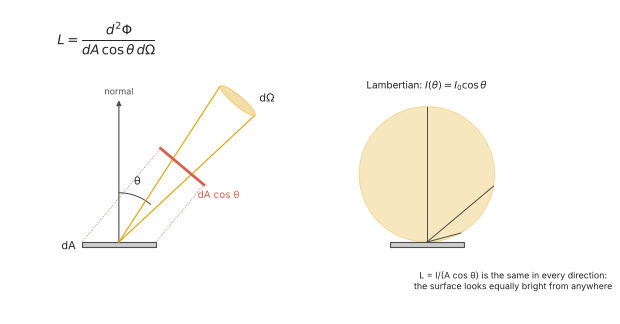

In [2]:
fig, ax = plt.subplots(figsize=(13, 5))
sketch.radiance_geometry(ax)
plt.show()

## 1. The four quantities

A source sends the **flux** $\Phi$ (W) into space. The **solid angle**
of a cone of half angle $\theta$ is $\Omega = 2\pi(1 - \cos\theta)$ sr
(the whole sphere is $4\pi$). Per solid angle, the flux is the
**intensity** $I = d\Phi/d\Omega$ (W/sr). This is the natural quantity
for a source that is small compared to its distance. Per area of a
surface, the flux is the **irradiance** $E = d\Phi/dA$ (W/m²) for light
that arrives and the **exitance** $M$ for light that leaves. Per area and
solid angle, it is the **radiance**

$$L = \frac{d^2\Phi}{dA\,\cos\theta\,d\Omega}\qquad(\mathrm{W\,m^{-2}\,sr^{-1}}),$$

with the area projected onto the direction of view, $dA\cos\theta$
(sketch above). Radiance is what a camera pixel or a cone of the retina
measures of an extended source. Each pixel sees a fixed solid angle and
collects through a fixed pupil. It is the "brightness" of the source.

| quantity | radiometric | photometric | photon |
|---|---|---|---|
| flux $\Phi$ | W | lumen (lm) | photons/s |
| intensity $I = d\Phi/d\Omega$ | W/sr | candela (cd = lm/sr) | photons s⁻¹ sr⁻¹ |
| irradiance, exitance $E, M = d\Phi/dA$ | W/m² | lux (lx = lm/m²) | photons s⁻¹ m⁻² |
| radiance $L$ | W m⁻² sr⁻¹ | cd/m² (nit) | photons s⁻¹ m⁻² sr⁻¹ |

Each quantity also has a spectral version per nm, written $\Phi_\lambda$,
$L_\lambda$ and so on.

A **Lambertian** surface has the same radiance in all directions. Then
$I(\theta) = L A\cos\theta$, and integrating over the hemisphere gives the
exitance

$$M = \int L\cos\theta\,d\Omega = L\int_0^{2\pi}\!\!\int_0^{\pi/2}\cos\theta\sin\theta\,d\theta\,d\varphi = \pi L,$$

with $\pi$, not $2\pi$, because the weight $\cos\theta$ favours the
directions near the normal. The test object is a Lambertian disk of radius
1 mm that emits 1 W, traced with 4 million rays from
`il.LambertianSource`. A simulated goniometer measures the intensity.
Planes in front of the disk measure the irradiance, which on a parallel
plane at the distance $z$ is exactly

$$E(\rho) = \frac{\pi L}{2}\left[1 - \frac{z^2 + \rho^2 - a^2}{\sqrt{(z^2 + \rho^2 + a^2)^2 - 4\rho^2a^2}}\right],$$

and $\pi L a^2/(a^2 + z^2)$ on the axis (notebook 88, LED optics).

In [3]:
# a Lambertian disk, radius a = 1 mm, 1 W into the hemisphere
a, P_src = 1.0, 1.0
src = il.LambertianSource(a, na=1.0, power=P_src)
A = np.pi*a**2
L = src.radiance                      # W mm^-2 sr^-1
print("area {:.4f} mm², étendue {:.4f} mm² sr, radiance L = P/(π A) = {:.5f} W mm⁻² sr⁻¹".format(
    A, src.etendue, L))
print("exitance M = P/A = {:.5f} W/mm² = π L = {:.5f}".format(P_src/A, np.pi*L))

n_rays = 4_000_000
R = src.rays(n_rays, rng=rng)
P0, D0 = R.points, R.directions
w = P_src/n_rays

# intensity against the polar angle (simulated goniometer)
edges = np.deg2rad(np.linspace(0, 90, 31))
I_mc, th = il.intensity_profile(D0, w, edges)
L_mc = I_mc/(A*np.cos(th))

# irradiance on parallel planes at z = a and z = 3a
def disk_irradiance(rho, z, a, L):
    """Exact irradiance of a Lambertian disk on a parallel plane at the distance z."""
    s = z**2 + rho**2 - a**2
    return np.pi*L/2*(1 - s/np.sqrt((z**2 + rho**2 + a**2)**2 - 4*rho**2*a**2))

planes = {}
for z in (1.0, 3.0):
    H = P0[:, :2] + (z/D0[:, 2])[:, None]*D0[:, :2]
    r = np.hypot(H[:, 0], H[:, 1])
    r_edges = np.linspace(0, 5*z, 41)
    Pr = np.histogram(r, r_edges, weights=np.full(n_rays, w))[0]
    E_mc = Pr/(np.pi*np.diff(r_edges**2))
    rc = 0.5*(r_edges[1:] + r_edges[:-1])
    planes[z] = (rc, E_mc)
    print("z = {:.0f} a: on-axis E = {:.5f} (Monte Carlo, first ring), exact {:.5f}, inverse square {:.5f}".format(
        z, E_mc[0], disk_irradiance(0.0, z, a, L), L*A/z**2))

area 3.1416 mm², étendue 9.8696 mm² sr, radiance L = P/(π A) = 0.10132 W mm⁻² sr⁻¹
exitance M = P/A = 0.31831 W/mm² = π L = 0.31831


z = 1 a: on-axis E = 0.15893 (Monte Carlo, first ring), exact 0.15915, inverse square 0.31831


z = 3 a: on-axis E = 0.03131 (Monte Carlo, first ring), exact 0.03183, inverse square 0.03537


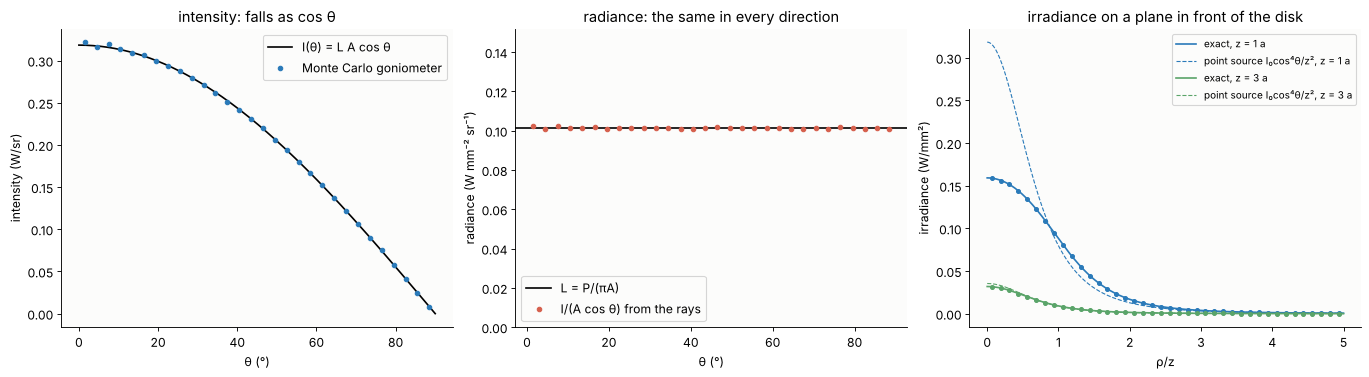

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.6), layout="constrained")
tt = np.linspace(0, np.pi/2, 200)
ax[0].plot(np.rad2deg(tt), L*A*np.cos(tt), color="k", label="I(θ) = L A cos θ")
ax[0].plot(np.rad2deg(th), I_mc, "o", ms=4, color=BLUE, label="Monte Carlo goniometer")
ax[0].set_xlabel("θ (°)")
ax[0].set_ylabel("intensity (W/sr)")
ax[0].set_title("intensity: falls as cos θ")
ax[0].legend()
ax[1].axhline(L, color="k", label="L = P/(πA)")
ax[1].plot(np.rad2deg(th), L_mc, "o", ms=4, color=RED, label="I/(A cos θ) from the rays")
ax[1].set_ylim(0, 1.5*L)
ax[1].set_xlabel("θ (°)")
ax[1].set_ylabel("radiance (W mm⁻² sr⁻¹)")
ax[1].set_title("radiance: the same in every direction")
ax[1].legend(loc="lower left")
for z, c in ((1.0, BLUE), (3.0, GREEN)):
    rc, E_mc = planes[z]
    rr = np.linspace(0, 5*z, 300)
    ax[2].plot(rr/z, disk_irradiance(rr, z, a, L), color=c, label="exact, z = {:.0f} a".format(z))
    ax[2].plot(rc/z, E_mc, "o", ms=3.5, color=c)
    ax[2].plot(rr/z, L*A*z**2/(z**2 + rr**2)**2, "--", color=c, lw=1,
               label="point source I₀cos⁴θ/z², z = {:.0f} a".format(z))
ax[2].set_xlabel("ρ/z")
ax[2].set_ylabel("irradiance (W/mm²)")
ax[2].set_title("irradiance on a plane in front of the disk")
ax[2].legend(fontsize=9)
plt.show()

The goniometer follows $LA\cos\theta$, and dividing it by the projected
area gives the same radiance at every angle, $P/(\pi A)$ = 0.1013
W mm⁻² sr⁻¹: the disk is Lambertian, as built. The irradiance on the two
planes follows the exact formula. Close to the disk ($z = a$) the axis
gets half of what a point source of the same intensity would give there
(0.159 against 0.318 W/mm²), because much of the disk is seen obliquely
and from farther away. At $z = 3a$ the point source is still 11 % too
high, the $a^2/z^2$ of the photometric distance. Far from the axis both
fall as $I_0\cos^4\theta/z^2$: one $\cos\theta$ from the intensity of the
Lambertian emitter, $\cos^2\theta$ from the longer distance and one more
from the tilt of the plane against the light.

## 2. Radiance along a ray and across an interface

Walk away from a lamp and the irradiance it gives you falls as $1/z^2$.
A white wall, though, does not look darker from across the room than from
close up. The eye measures radiance: each receptor sees a fixed solid
angle through a fixed pupil. Moving away, the patch of wall in that solid
angle grows as $z^2$, and the share of its light that enters the pupil
falls as $1/z^2$. The two cancel. In the language of notebook 83 (étendue), the
basic radiance $L/n^2$ is the power per phase space volume,

$$\frac{L}{n^2} = \frac{d^4\Phi}{dx\,dy\,dp\,dq},\qquad dp\,dq = n^2\cos\theta\,d\Omega,$$

and a lossless system only moves phase space around without compressing
it. So the basic radiance is carried unchanged along every ray.

At an interface into glass, Snell's law keeps the optical direction
cosines $p = n\sin\theta$, so the phase space volume stays the same, and
only the Fresnel transmittance $T$ takes away power. The basic radiance
falls by $T$. The radiance itself grows, because the same light now
travels in a smaller cone:

$$\frac{L'}{n'^2} = T\,\frac{L}{n^2},\qquad L' = n^2\,T\,L\quad(\text{from air into glass of index } n).$$

The test uses a Lambertian disk that emits only into NA = 0.12. It has
the same radiance as the full disk, and its rays fill a small box of
phase space around the axis densely. That box is sampled at several
distances, and after refraction into glass of $n = 1.5$ with the
unpolarized Fresnel transmittance ($T_s$ and $T_p$ from
`pyoptics.interfaces`). Then the full disk of section 1 shines into the
glass, and the radiance in the glass is measured against the angle.

In [5]:
# radiance in phase space along the axis. A Lambertian disk that emits only into NA = 0.12 has the
# same radiance; its rays fill the small box around x = y = 0, p = q = 0 densely.
def basic_radiance(points, dirs, weights, n=1.0, dx=0.2, dp=0.04):
    """Power per phase space volume in a small box at the origin: L/n²."""
    X = il.phase_space(points, dirs, n)
    box = (np.abs(X[:, 0]) < dx) & (np.abs(X[:, 1]) < dx) & (np.abs(X[:, 2]) < dp) & (np.abs(X[:, 3]) < dp)
    return np.sum(weights[box])/(2*dx)**2/(2*dp)**2, box.sum()

na_s = 0.12
src_s = il.LambertianSource(a, na=na_s, power=P_src*na_s**2)
n_s = 2_000_000
Rs = src_s.rays(n_s, rng=rng)
Ps, Ds = Rs.points, Rs.directions
Ws = np.full(n_s, src_s.power/n_s)
print("NA = {} source: radiance {:.5f} W mm⁻² sr⁻¹ (the full disk: {:.5f})".format(na_s, src_s.radiance, L))
zs = np.array([0.0, 2.0, 5.0, 10.0, 15.0])
Lz = []
print(" z (mm)   L/n² from the rays   rays in the box")
for z in zs:
    Pz = Ps + (z/Ds[:, 2])[:, None]*Ds
    Lb, nb = basic_radiance(Pz, Ds, Ws)
    Lz.append(Lb)
    print("{:6.1f}    {:.5f}             {:6d}".format(z, Lb, nb))
Lz = np.array(Lz)

# into glass: refraction at a plane z = 0+, with the Fresnel transmittance (unpolarized)
n_g = 1.5
T0 = 1 - ((n_g - 1)/(n_g + 1))**2
Dg = il.refract_plane(Ds, 1.0, n_g)
th_i = np.arccos(Ds[:, 2])
Tf = 0.5*(interfaces.T_s(th_i, 1.0, n_g) + interfaces.T_p(th_i, 1.0, n_g))
Lb_air = basic_radiance(Ps, Ds, Ws, 1.0)[0]
Lb_g = basic_radiance(Ps, Dg, Ws*Tf, n_g)[0]
print("basic radiance L/n²: air {:.5f}, glass {:.5f}, ratio {:.4f} (Fresnel T at normal incidence {:.4f})".format(
    Lb_air, Lb_g, Lb_g/Lb_air, T0))

# the full hemisphere into glass, radiance against the angle in the glass
W0 = np.full(n_rays, w)
Dg = il.refract_plane(D0, 1.0, n_g)
theta_i = np.arccos(D0[:, 2])
Wg = W0*0.5*(interfaces.T_s(theta_i, 1.0, n_g) + interfaces.T_p(theta_i, 1.0, n_g))
edges_g = np.deg2rad(np.linspace(0, 41, 21))
I_g, th_g = il.intensity_profile(Dg, Wg, edges_g)
L_g = I_g/(A*np.cos(th_g))

NA = 0.12 source: radiance 0.10132 W mm⁻² sr⁻¹ (the full disk: 0.10132)
 z (mm)   L/n² from the rays   rays in the box
   0.0    0.10142              14424


   2.0    0.10175              14471
   5.0    0.10088              14348


  10.0    0.10187              14488
  15.0    0.10135              14414


basic radiance L/n²: air 0.10142, glass 0.09736, ratio 0.9600 (Fresnel T at normal incidence 0.9600)


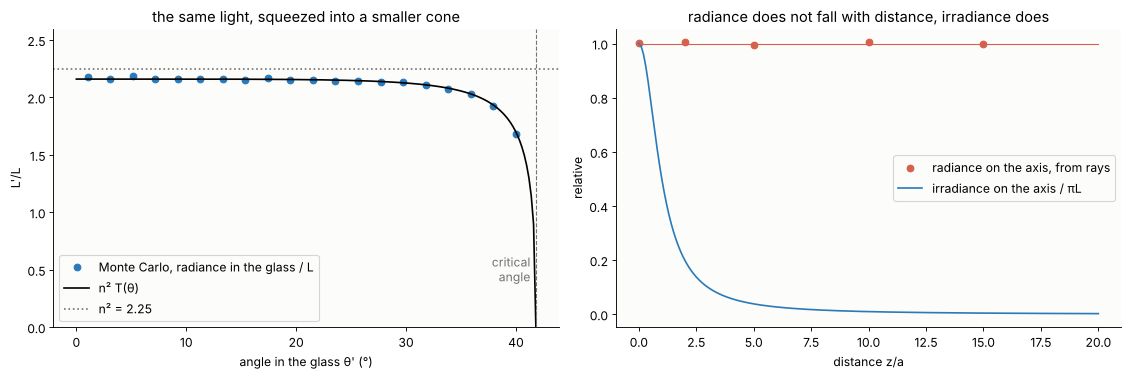

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6), layout="constrained")
ax[0].plot(np.rad2deg(th_g), L_g/L, "o", color=BLUE, label="Monte Carlo, radiance in the glass / L")
tg = np.linspace(0, np.arcsin(1/n_g), 200)
ti = np.arcsin(n_g*np.sin(tg))
ax[0].plot(np.rad2deg(tg), n_g**2*0.5*(interfaces.T_s(ti, 1.0, n_g) + interfaces.T_p(ti, 1.0, n_g)),
           color="k", label="n² T(θ)")
ax[0].axhline(n_g**2, color=GREY, ls=":", label="n² = {:.2f}".format(n_g**2))
ax[0].axvline(np.rad2deg(np.arcsin(1/n_g)), color=GREY, ls="--", lw=1)
ax[0].text(np.rad2deg(np.arcsin(1/n_g)) - 0.5, 0.4, "critical\nangle", ha="right", color=GREY)
ax[0].set_ylim(0, 2.6)
ax[0].set_xlabel("angle in the glass θ' (°)")
ax[0].set_ylabel("L'/L")
ax[0].set_title("the same light, squeezed into a smaller cone")
ax[0].legend(loc="lower left")
d = np.linspace(0, 20, 200)
ax[1].plot(zs/a, Lz/L, "o", color=RED, label="radiance on the axis, from rays")
ax[1].plot(d, np.pi*L*a**2/(a**2 + d**2)/(np.pi*L), color=BLUE, label="irradiance on the axis / πL")
ax[1].plot(d, np.ones_like(d), color=RED, lw=1)
ax[1].set_xlabel("distance z/a")
ax[1].set_ylabel("relative")
ax[1].set_title("radiance does not fall with distance, irradiance does")
ax[1].legend()
plt.show()

The power per phase space volume on the axis stays at $L$ to the
Monte Carlo noise of 1 % (about 14,000 rays per box) from the disk out to
15 mm, while the irradiance on the axis falls to 0.4 % of $\pi L$. Into
glass the basic radiance drops by the Fresnel transmittance at normal
incidence, 0.960, and the radiance in the glass is $n^2T$ = 2.16 times
that in air: the light of the whole hemisphere is squeezed into the cone
of the critical angle, 41.8°. Near the critical angle the grazing
incidence in air lets less light in, and the radiance falls.

Two consequences run through the other notebooks. An optical system can
never make a source look brighter than it is, in basic radiance:
notebook 83 (étendue) derives the limit of solar concentration from it, and
notebook 106 (radiometry of images) the brightness of images. And an absorber or a detector
immersed in glass can receive $n^2$ times more irradiance than one in air
from the same source, which is why concentrators and LED domes are made
of solid dielectric.

## 3. Black bodies

A black body absorbs all the light that falls on it. In equilibrium it
emits the spectral radiance given by Planck's law,

$$L_\lambda(T) = \frac{2hc^2}{\lambda^5}\,\frac{1}{e^{hc/\lambda k_BT} - 1},$$

the same in every direction (a Lambertian emitter). Its peak lies at
$\lambda_\mathrm{max} = b/T$ with $b$ = 2898 µm K (Wien), and its
integral is $\sigma T^4/\pi$, so its exitance is $\sigma T^4$
(Stefan–Boltzmann). `rad.planck_radiance()` gives absolute values in
W m⁻² sr⁻¹ nm⁻¹ (`colour.planck()`, used for colours, gives only the
shape). The Sun is close to a black body of 5772 K, its effective
temperature, with the angular radius 4.65 mrad. The irradiance it gives
at the Earth then follows from radiance and solid angle alone,
$E = L\pi\sin^2\alpha$, the projected solid angle of a small cone.

Sun as a 5772 K black body: radiance 2.003e+07 W m⁻² sr⁻¹, solid angle 6.800e-05 sr
irradiance at 1 AU = L π sin²α = 1362 W/m² (measured total solar irradiance 1361 W/m²)
luminance of the Sun 1.84e+09 cd/m², illuminance at 1 AU 125 klx
  1800 K: exitance 5.953e+05 W/m², peak  1610 nm, visible share  0.8 %
  2856 K: exitance 3.773e+06 W/m², peak  1015 nm, visible share 10.5 %
  4000 K: exitance 1.452e+07 W/m², peak   724 nm, visible share 28.6 %
  5772 K: exitance 6.294e+07 W/m², peak   502 nm, visible share 46.5 %
 10000 K: exitance 5.670e+08 W/m², peak   290 nm, visible share 40.4 %


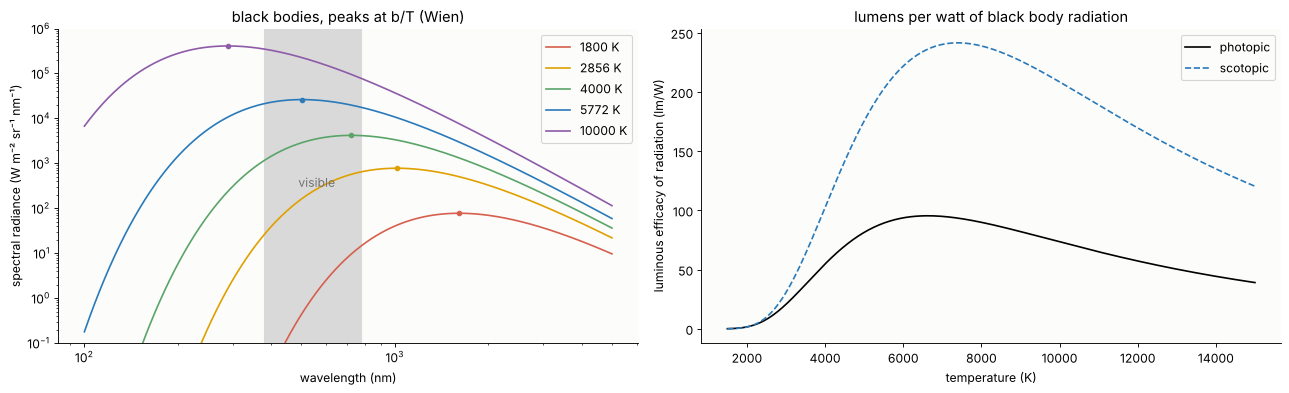

In [7]:
lam = np.linspace(100, 5000, 20000)
fig, ax = plt.subplots(1, 2, figsize=(16, 4.8), layout="constrained")
for T, c in ((1800, RED), (2856, ORANGE), (4000, GREEN), (5772, BLUE), (10000, PURPLE)):
    Ll = rad.planck_radiance(lam, T)
    ax[0].loglog(lam, Ll, color=c, label="{} K".format(T))
    ax[0].plot(rad.wien_peak(T), rad.planck_radiance(rad.wien_peak(T), T), "o", color=c, ms=4)
ax[0].axvspan(380, 780, color="0.85", zorder=0)
ax[0].text(560, 3e2, "visible", ha="center", color=GREY)
ax[0].set_ylim(1e-1, 1e6)
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("spectral radiance (W m⁻² sr⁻¹ nm⁻¹)")
ax[0].set_title("black bodies, peaks at b/T (Wien)")
ax[0].legend()

T_sun = il.SUN_TEMPERATURE
L_sun = rad.blackbody_radiance(T_sun)
E_sun = L_sun*np.pi*np.sin(il.SUN_ANGULAR_RADIUS)**2
print("Sun as a {:.0f} K black body: radiance {:.3e} W m⁻² sr⁻¹, solid angle {:.3e} sr".format(
    T_sun, L_sun, rad.solid_angle_cone(il.SUN_ANGULAR_RADIUS)))
print("irradiance at 1 AU = L π sin²α = {:.0f} W/m² (measured total solar irradiance {:.0f} W/m²)".format(
    E_sun, rad.SOLAR_CONSTANT))
lv = np.linspace(360, 830, 4001)
Lv_sun = rad.luminous_flux(lv, rad.planck_radiance(lv, T_sun))
print("luminance of the Sun {:.2e} cd/m², illuminance at 1 AU {:.0f} klx".format(
    Lv_sun, Lv_sun*np.pi*np.sin(il.SUN_ANGULAR_RADIUS)**2/1e3))

# share of the radiation in the visible
for T in (1800, 2856, 4000, 5772, 10000):
    vis = np.trapezoid(rad.planck_radiance(lv[(lv >= 380) & (lv <= 780)], T), lv[(lv >= 380) & (lv <= 780)])
    print("{:6d} K: exitance {:9.3e} W/m², peak {:5.0f} nm, visible share {:4.1f} %".format(
        T, np.pi*rad.blackbody_radiance(T), rad.wien_peak(T), 100*vis/rad.blackbody_radiance(T)))
TT = np.linspace(1500, 15000, 300)
ax[1].plot(TT, rad.blackbody_efficacy(TT), color="k", label="photopic")
ax[1].plot(TT, rad.blackbody_efficacy(TT, scotopic=True), color=BLUE, ls="--", label="scotopic")
ax[1].set_xlabel("temperature (K)")
ax[1].set_ylabel("luminous efficacy of radiation (lm/W)")
ax[1].set_title("lumens per watt of black body radiation")
ax[1].legend()
plt.show()

From the temperature and the angular size alone the irradiance at 1 AU
is 1362 W/m², against the measured 1361 W/m². The effective temperature
is defined from the Sun's total output, so this checks the units rather
than measuring anything. The luminance of the Sun comes out as
1.8 × 10⁹ cd/m² and its illuminance above the atmosphere as 125 klx. The
measured values are about 1.6 × 10⁹ cd/m² and 128 klx, the difference
being that the real solar spectrum is not exactly a black body. A tungsten
filament at 2856 K (the CIE illuminant A) puts only 10.5 % of its
radiation into the visible and peaks in the infrared, at 1015 nm. The
right panel anticipates section 4: black body radiation never gives more
than 95 lm/W, at about 6600 K.

## 4. Photometry: from watts to lumens

The eye is not equally sensitive to all wavelengths. In daylight, cone
(photopic) vision has the spectral luminous efficiency $V(\lambda)$,
which peaks near 555 nm. At night, rod (scotopic) vision has
$V'(\lambda)$, which peaks at 507 nm. Photometric quantities weight the
spectral radiometric ones with them:

$$\Phi_v = K_m\int V(\lambda)\,\Phi_{e,\lambda}\,d\lambda,\qquad K_m = 683\ \mathrm{lm/W},\qquad K_m' = 1700\ \mathrm{lm/W}.$$

The constants come from the SI definition of the candela: monochromatic
light of 540 THz (555.17 nm in vacuum) with the radiant intensity
1/683 W/sr has the luminous intensity 1 cd. So photometric quantities are
radiometric ones in disguise, with a fixed spectral weight. The table of
section 1 holds for both.

$V(\lambda)$ and $V'(\lambda)$ are defined by tables, at 1 nm steps
(CIE 018:2019, ISO 23539/CIE S 010). `pyoptics.radiometry` uses analytic
fits instead. The photopic one is the CIE 1931 $\bar y$ of
`colour.cie_xyz()`, which equals $V(\lambda)$ by definition, a sum of
two-sided Gaussians after Wyman, Sloan and Shirley. The scotopic one is a
fit of the same form. For calibration work, use the tables. Below, the
fits are compared with samples of the tables at 10 nm.

The **luminous efficacy of radiation**, $K = \Phi_v/\Phi_e$, says how
many lumens a spectrum gives per watt of light. A lamp's own luminous
efficacy, in lumens per watt of electrical power, is that number times
the lamp's wall plug efficiency. Here it is computed for black bodies, for
a phosphor converted white LED (a blue die at 450 nm and a broad yellow
phosphor band at 560 nm, with 25 % or 15 % of the power left in the blue)
and for lasers.

In [8]:
# samples of the CIE tables at 10 nm, for comparison with the fits in pyoptics.radiometry
lam_cie = np.arange(380, 781, 10.0)
V_cie = np.array([3.9e-5, 1.2e-4, 3.96e-4, 1.21e-3, 4.0e-3, 0.0116, 0.023, 0.038, 0.060, 0.09098, 0.13902,
                  0.20802, 0.323, 0.503, 0.710, 0.862, 0.954, 0.99495, 0.995, 0.952, 0.870, 0.757, 0.631,
                  0.503, 0.381, 0.265, 0.175, 0.107, 0.061, 0.032, 0.017, 0.00821, 0.004102, 0.002091,
                  0.001047, 5.2e-4, 2.49e-4, 1.2e-4, 6.0e-5, 3.0e-5, 1.5e-5])
Vs_cie = np.array([5.89e-4, 2.209e-3, 9.29e-3, 0.03484, 0.0966, 0.1998, 0.3281, 0.455, 0.567, 0.676, 0.793,
                   0.904, 0.982, 0.997, 0.935, 0.811, 0.650, 0.481, 0.3288, 0.2076, 0.1212, 0.0655, 0.03315,
                   0.01593, 0.00737, 0.003335, 0.001497, 6.77e-4, 3.129e-4, 1.48e-4, 7.15e-5, 3.533e-5,
                   1.78e-5, 9.14e-6, 4.78e-6, 2.546e-6, 1.379e-6, 7.6e-7, 4.25e-7, 2.41e-7, 1.39e-7])
print("largest deviation of the fits from the table: photopic {:.4f}, scotopic {:.4f}".format(
    np.max(np.abs(rad.V_photopic(lam_cie) - V_cie)), np.max(np.abs(rad.V_scotopic(lam_cie) - Vs_cie))))
print("integrals over 380-780 nm (fit/table): photopic {:.4f}, scotopic {:.4f}".format(
    np.trapezoid(rad.V_photopic(np.linspace(380, 780, 4001)), dx=0.1)/np.trapezoid(V_cie, dx=10),
    np.trapezoid(rad.V_scotopic(np.linspace(380, 780, 4001)), dx=0.1)/np.trapezoid(Vs_cie, dx=10)))
print("K_m V(555.17 nm) = {:.1f} lm/W (the SI: 683 lm/W at 540 THz)".format(rad.K_M*rad.V_photopic(555.17)))


def gauss(lam, centre, fwhm):
    return np.exp(-4*np.log(2)*(lam - centre)**2/fwhm**2)


# a phosphor converted white LED: blue die and a yellow phosphor
def white_led(lam, blue_share):
    b = gauss(lam, 450, 20)
    y = gauss(lam, 560, 110)
    return blue_share*b/np.trapezoid(b, lam) + (1 - blue_share)*y/np.trapezoid(y, lam)


sources = {}
sources["tungsten, 2856 K (all wavelengths)"] = rad.blackbody_efficacy(2856)
sources["the Sun, 5772 K black body"] = rad.blackbody_efficacy(5772)
sources["best black body, 6600 K"] = rad.blackbody_efficacy(6600)
for share in (0.25, 0.15):
    sources["white LED, {:.0f} % blue".format(100*share)] = rad.luminous_efficacy(lv, white_led(lv, share))
rgb = gauss(lv, 450, 2) + 1.1*gauss(lv, 532, 2) + 1.4*gauss(lv, 638, 2)
sources["RGB lasers 450/532/638 nm"] = rad.luminous_efficacy(lv, rgb)
sources["green laser 532 nm"] = rad.K_M*rad.V_photopic(532)
sources["555 nm, the maximum"] = rad.K_M*rad.V_photopic(555)
for k, v in sources.items():
    print("{:38s} {:6.1f} lm/W".format(k, v))

largest deviation of the fits from the table: photopic 0.0070, scotopic 0.0060
integrals over 380-780 nm (fit/table): photopic 1.0006, scotopic 1.0037
K_m V(555.17 nm) = 681.6 lm/W (the SI: 683 lm/W at 540 THz)
tungsten, 2856 K (all wavelengths)       16.5 lm/W
the Sun, 5772 K black body               92.1 lm/W
best black body, 6600 K                  95.5 lm/W
white LED, 25 % blue                    354.6 lm/W
white LED, 15 % blue                    398.6 lm/W
RGB lasers 450/532/638 nm               249.7 lm/W
green laser 532 nm                      607.4 lm/W
555 nm, the maximum                     681.7 lm/W


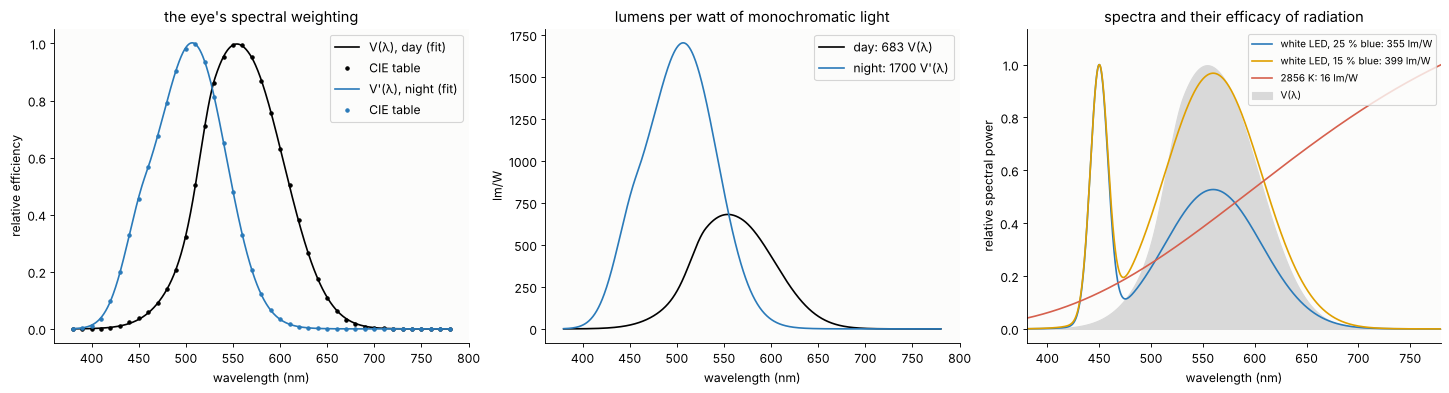

In [9]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), layout="constrained")
ll = np.linspace(380, 780, 801)
ax[0].plot(ll, rad.V_photopic(ll), color="k", label="V(λ), day (fit)")
ax[0].plot(lam_cie, V_cie, "o", ms=3, color="k", label="CIE table")
ax[0].plot(ll, rad.V_scotopic(ll), color=BLUE, label="V'(λ), night (fit)")
ax[0].plot(lam_cie, Vs_cie, "o", ms=3, color=BLUE, label="CIE table")
ax[0].set_xlabel("wavelength (nm)")
ax[0].set_ylabel("relative efficiency")
ax[0].set_title("the eye's spectral weighting")
ax[0].legend()
ax[1].plot(ll, rad.K_M*rad.V_photopic(ll), color="k", label="day: 683 V(λ)")
ax[1].plot(ll, rad.K_M_SCOTOPIC*rad.V_scotopic(ll), color=BLUE, label="night: 1700 V'(λ)")
ax[1].set_xlabel("wavelength (nm)")
ax[1].set_ylabel("lm/W")
ax[1].set_title("lumens per watt of monochromatic light")
ax[1].legend()
for share, c in ((0.25, BLUE), (0.15, ORANGE)):
    ax[2].plot(lv, white_led(lv, share)/white_led(lv, share).max(), color=c,
               label="white LED, {:.0f} % blue: {:.0f} lm/W".format(100*share, rad.luminous_efficacy(lv, white_led(lv, share))))
bb = rad.planck_radiance(lv, 2856)
ax[2].plot(lv, bb/bb[(lv > 380) & (lv < 780)].max(), color=RED,
           label="2856 K: {:.0f} lm/W".format(rad.blackbody_efficacy(2856)))
ax[2].fill_between(lv, rad.V_photopic(lv), color="0.85", label="V(λ)")
ax[2].set_xlim(380, 780)
ax[2].set_xlabel("wavelength (nm)")
ax[2].set_ylabel("relative spectral power")
ax[2].set_title("spectra and their efficacy of radiation")
ax[2].legend(fontsize=9)
plt.show()

The fits stay within 0.007 (photopic) and 0.006 (scotopic) of the tables,
and their integrals within 0.4 %. The photopic fit peaks at 0.998, so it
gives 681.6 instead of 683 lm/W at 540 THz. That 0.2 % matters only in a
standards laboratory.

| spectrum | lm per W of light |
|---|---|
| tungsten, 2856 K (all wavelengths) | 16.5 |
| the Sun as a 5772 K black body | 92 |
| best black body, 6600 K | 95.5 |
| white LED, 25 % blue / 15 % blue | 355 / 399 |
| RGB lasers 450/532/638 nm (power 1 : 1.1 : 1.4) | 250 |
| green laser, 532 nm | 607 |
| 555 nm, the maximum | 682 |

- A black body wastes most of its power outside the visible and gives at
  most 95 lm/W. A tungsten lamp gets about 16 lm out of each watt of its
  radiation, and since nearly all of the electrical power is radiated,
  that is also roughly its luminous efficacy.
- A white LED reaches 350 to 400 lm per watt of light, more when less
  blue gets through (a warmer white). With a wall plug efficiency of 40 to
  50 %, that is the 150 to 200 lm/W of good LED lamps today.
- Narrow lines can do better or worse: a green laser gives 607 lm/W, but
  a white made of red, green and blue lines only 250 here, because 450 and
  638 nm sit far down the flanks of $V(\lambda)$.
- The maximum, 683 lm/W, is for green light near 555 nm alone. No white
  light reaches it.

In [10]:
# Purkinje shift: a red and a blue patch of equal luminance by day
lam_r, lam_b = 620.0, 470.0
# radiances that give 1 cd/m² each by day
Le_r, Le_b = 1/(rad.K_M*rad.V_photopic(lam_r)), 1/(rad.K_M*rad.V_photopic(lam_b))
s_r, s_b = rad.K_M_SCOTOPIC*rad.V_scotopic(lam_r)*Le_r, rad.K_M_SCOTOPIC*rad.V_scotopic(lam_b)*Le_b
print("radiance for 1 cd/m² by day: red {:.2e}, blue {:.2e} W m⁻² sr⁻¹".format(Le_r, Le_b))
print("scotopic luminance: red {:.3f}, blue {:.2f} cd/m²; at night blue looks {:.0f} times brighter".format(
    s_r, s_b, s_b/s_r))
print("S/P ratio (scotopic/photopic lumens): 2856 K {:.2f}, 5772 K {:.2f}, white LED 25 % blue {:.2f}".format(
    rad.blackbody_efficacy(2856, True)/rad.blackbody_efficacy(2856),
    rad.blackbody_efficacy(5772, True)/rad.blackbody_efficacy(5772),
    rad.luminous_efficacy(lv, white_led(lv, 0.25), True)/rad.luminous_efficacy(lv, white_led(lv, 0.25))))

radiance for 1 cd/m² by day: red 3.92e-03, blue 1.64e-02 W m⁻² sr⁻¹
scotopic luminance: red 0.051, blue 18.75 cd/m²; at night blue looks 365 times brighter
S/P ratio (scotopic/photopic lumens): 2856 K 1.42, 5772 K 2.32, white LED 25 % blue 2.02


At dusk the rods take over, and colours change their relative brightness:
red flowers turn dark before blue ones (Purkinje, 1825). Two patches with
the same luminance of 1 cd/m² by day, one at 620 nm and one at 470 nm,
differ by a factor of 365 for the rods: 0.05 against 18.8 scotopic cd/m².
The ratio of scotopic to photopic lumens of a source, its S/P ratio,
says how much its light helps night vision: 1.4 for the tungsten lamp,
2.0 for the white LED with 25 % blue and 2.3 for daylight.

## 5. Lambertian surfaces and the exchange of light

A matte surface that reflects the fraction $\rho$ of the irradiance $E$
diffusely is itself a Lambertian source, of radiance $L = \rho E/\pi$.
Between two Lambertian surfaces, the fraction of the light that leaves
surface 1 and reaches surface 2 is a purely geometric number, the
**view factor** (or configuration factor)

$$F_{12} = \frac{1}{A_1}\int_{A_1}\int_{A_2}\frac{\cos\theta_1\cos\theta_2}{\pi s^2}\,dA_2\,dA_1,$$

for the distance $s$ between two surface elements and the angles
$\theta_1, \theta_2$ from their normals. It obeys the reciprocity
$A_1F_{12} = A_2F_{21}$. Two coaxial parallel disks have a closed form
(`rad.view_factor_parallel_disks()`), and a small element facing a disk
of radius $a$ at the distance $d$ has $a^2/(a^2 + d^2)$
(`rad.view_factor_point_disk()`), the photometric distance of section 1
again. The Monte Carlo version launches Lambertian rays from disk 1 and
counts those that hit disk 2.

In [11]:
# view factors between coaxial parallel disks, Monte Carlo against the closed form
r1 = 1.0
ratios = np.array([0.25, 0.5, 1.0, 2.0, 4.0])
n_mc = 400_000
Pm = il.disk_points(n_mc, r1, rng)
Dm = il.lambertian_directions(n_mc, rng=rng)
F_mc = {}
for r2 in (0.5, 1.0, 2.0):
    vals = []
    for dist in ratios:
        t = dist/Dm[:, 2]
        vals.append(np.mean(np.hypot(Pm[:, 0] + t*Dm[:, 0], Pm[:, 1] + t*Dm[:, 1]) <= r2))
    F_mc[r2] = np.array(vals)
    print("r2 = {:.1f}: Monte Carlo".format(r2), np.round(F_mc[r2], 4), " exact",
          np.round(rad.view_factor_parallel_disks(r1, r2, ratios), 4))
print("reciprocity A1 F12 = A2 F21 at d = 1: {:.5f} = {:.5f}".format(
    r1**2*rad.view_factor_parallel_disks(r1, 2.0, 1.0), 2.0**2*rad.view_factor_parallel_disks(2.0, r1, 1.0)))

r2 = 0.5: Monte Carlo [0.2311 0.1907 0.1164 0.0476 0.0141]  exact [0.2312 0.191  0.1172 0.0481 0.0145]
r2 = 1.0: Monte Carlo [0.7786 0.6089 0.381  0.1711 0.0553]  exact [0.7793 0.6096 0.382  0.1716 0.0557]


r2 = 2.0: Monte Carlo [0.9799 0.9248 0.7634 0.4677 0.1917]  exact [0.9797 0.9248 0.7639 0.4689 0.1922]
reciprocity A1 F12 = A2 F21 at d = 1: 0.76393 = 0.76393


An **integrating sphere** is a hollow sphere with a white, diffusely
reflecting wall ($\rho$ = 0.95 to 0.99) and a few small ports. Light that
enters is reflected many times, and the wall becomes a uniform Lambertian
source. Two properties make this simple. First, for two points on a
sphere, $\cos\theta_1\cos\theta_2/s^2 = 1/(4R^2)$, so the view factor
from any point of the wall to any patch of it is just the patch's share
of the sphere's area: a single diffuse reflection spreads light uniformly
over the whole sphere. Second, the bounces then form a geometric series.
If the flux $\Phi$ first hits the wall, the wall radiance is

$$L = \frac{\Phi}{\pi A_s}\,\frac{\rho}{1 - \rho(1 - f)},$$

for the wall area $A_s$ and the port fraction $f$ (the share of $A_s$
taken by the ports). The second factor, the **sphere multiplier**
(`rad.sphere_gain()`), can be 30 or more. A detector port of the fraction
$f_d$ receives $\rho f_d/(1 - \rho(1 - f))$ of the flux.
`rad.sphere_trace()` traces rays through the bounces. Here a beam of
300,000 rays enters a sphere of 100 mm radius through an input port
(8° half angle seen from the centre) and hits the opposite wall. A
detector port (5°) sits at 90° to the beam.

In [12]:
# integrating sphere: 100 mm radius, an input port and a detector port
R_s = 100.0
a_in, a_det = np.deg2rad(8.0), np.deg2rad(5.0)
f_in, f_det = (1 - np.cos(a_in))/2, (1 - np.cos(a_det))/2
f_tot = f_in + f_det
print("port fractions: input {:.4f}, detector {:.4f}".format(f_in, f_det))
ports = [([0, 0, -1], a_in), ([1, 0, 0], a_det)]
n_sp = 300_000
Pin = np.tile([0.0, 0.0, -0.999*R_s], (n_sp, 1))
Din = np.tile([0.0, 0.0, 1.0], (n_sp, 1))
rhos = np.array([0.5, 0.8, 0.9, 0.95, 0.98, 0.99])
det_mc = []
for rho in rhos:
    res = rad.sphere_trace(Pin, Din, R_s, rho, ports, power=1/n_sp, max_bounces=2000, rng=rng)
    det_mc.append(res.port_power[1])
det_mc = np.array(det_mc)
for rho, d_mc in zip(rhos, det_mc):
    print("ρ = {:.2f}: sphere multiplier {:6.2f}; power to the detector Monte Carlo {:.5f}, formula {:.5f}".format(
        rho, rad.sphere_gain(rho, f_tot), d_mc, rad.sphere_gain(rho, f_tot)*f_det))
g98 = rad.sphere_gain(0.98, f_tot)
print("at ρ = 0.98 a drop of the reflectance by 0.01 lowers the signal by {:.0f} %".format(
    100*(1 - rad.sphere_gain(0.97, f_tot)/g98)))
res = rad.sphere_trace(Pin, Din, R_s, 0.98, ports, power=1/n_sp, max_bounces=4, keep_hits=4, rng=rng)

port fractions: input 0.0049, detector 0.0019


ρ = 0.50: sphere multiplier   0.99; power to the detector Monte Carlo 0.00183, formula 0.00189
ρ = 0.80: sphere multiplier   3.89; power to the detector Monte Carlo 0.00732, formula 0.00741
ρ = 0.90: sphere multiplier   8.48; power to the detector Monte Carlo 0.01593, formula 0.01614
ρ = 0.95: sphere multiplier  16.83; power to the detector Monte Carlo 0.03228, formula 0.03203
ρ = 0.98: sphere multiplier  36.80; power to the detector Monte Carlo 0.07020, formula 0.07001
ρ = 0.99: sphere multiplier  59.28; power to the detector Monte Carlo 0.11217, formula 0.11279
at ρ = 0.98 a drop of the reflectance by 0.01 lowers the signal by 28 %


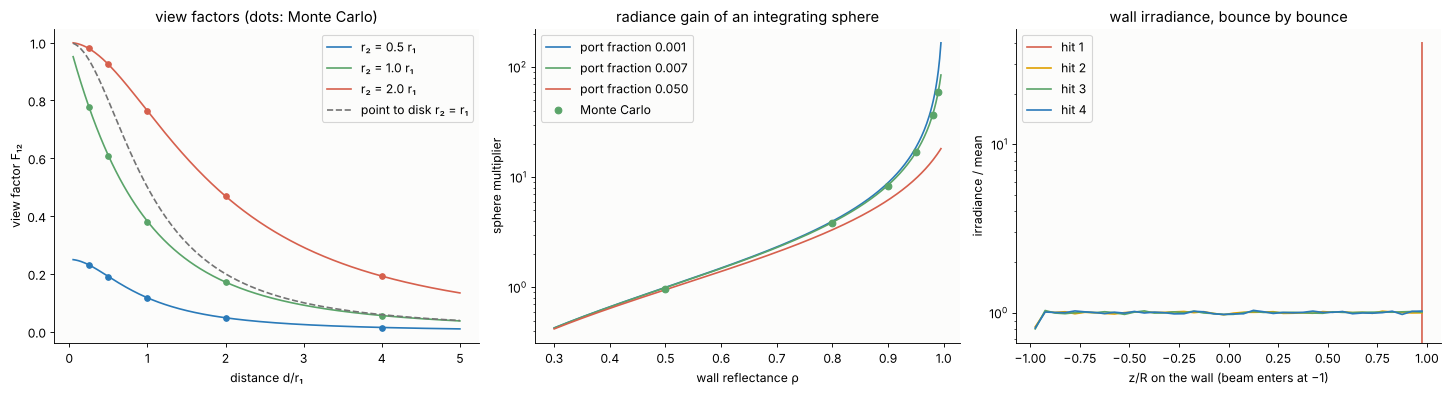

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(18, 4.8), layout="constrained")
dd = np.linspace(0.05, 5, 300)
for (r2, c) in ((0.5, BLUE), (1.0, GREEN), (2.0, RED)):
    ax[0].plot(dd, rad.view_factor_parallel_disks(r1, r2, dd), color=c, label="r₂ = {:.1f} r₁".format(r2))
    ax[0].plot(ratios, F_mc[r2], "o", color=c, ms=5)
ax[0].plot(dd, rad.view_factor_point_disk(1.0, dd), "--", color=GREY, label="point to disk r₂ = r₁")
ax[0].set_xlabel("distance d/r₁")
ax[0].set_ylabel("view factor F₁₂")
ax[0].set_title("view factors (dots: Monte Carlo)")
ax[0].legend()
rr = np.linspace(0.3, 0.995, 300)
for f, c in ((0.001, BLUE), (f_tot, GREEN), (0.05, RED)):
    ax[1].semilogy(rr, rad.sphere_gain(rr, f), color=c, label="port fraction {:.3f}".format(f))
ax[1].semilogy(rhos, det_mc/f_det, "o", color=GREEN, label="Monte Carlo")
ax[1].set_xlabel("wall reflectance ρ")
ax[1].set_ylabel("sphere multiplier")
ax[1].set_title("radiance gain of an integrating sphere")
ax[1].legend()
cz_edges = np.linspace(-1, 1, 41)
for k, c in zip(range(4), (RED, ORANGE, GREEN, BLUE)):
    Q, wq = res.hits[k]
    H = np.histogram(Q[:, 2]/R_s, cz_edges, weights=wq)[0]
    # uniform irradiance on the sphere = uniform in z (Archimedes)
    ax[2].semilogy(0.5*(cz_edges[1:] + cz_edges[:-1]), H/(2*np.pi*R_s**2*np.diff(cz_edges)/(4*np.pi*R_s**2))/wq.sum()
                   if wq.sum() > 0 else H, color=c, label="hit {}".format(k + 1))
ax[2].set_xlabel("z/R on the wall (beam enters at −1)")
ax[2].set_ylabel("irradiance / mean")
ax[2].set_title("wall irradiance, bounce by bounce")
ax[2].legend()
plt.show()

The view factors from Monte Carlo agree with the closed forms to the
third decimal, and the traced detector power follows the sphere formula
within 3 %, the Monte Carlo noise of the few hundred to few thousand
rays that reach the small detector port. The multiplier grows steeply with
the reflectance: 4 at $\rho$ = 0.8, 37 at 0.98 and 59 at 0.99. This is
also the sphere's weakness. At $\rho$ = 0.98 a drop of the reflectance
by 0.01 (dust, ageing of the coating) lowers the signal by 28 %. The
right panel shows the wall irradiance bounce by bounce. The first hit is
a spot opposite the input port. Every later bounce is uniform to the
noise, apart from the input port near $z = -R$. A detector that does not
see the first hit therefore measures the total flux, whatever the shape
of the beam, and real spheres have baffles to make sure of that.

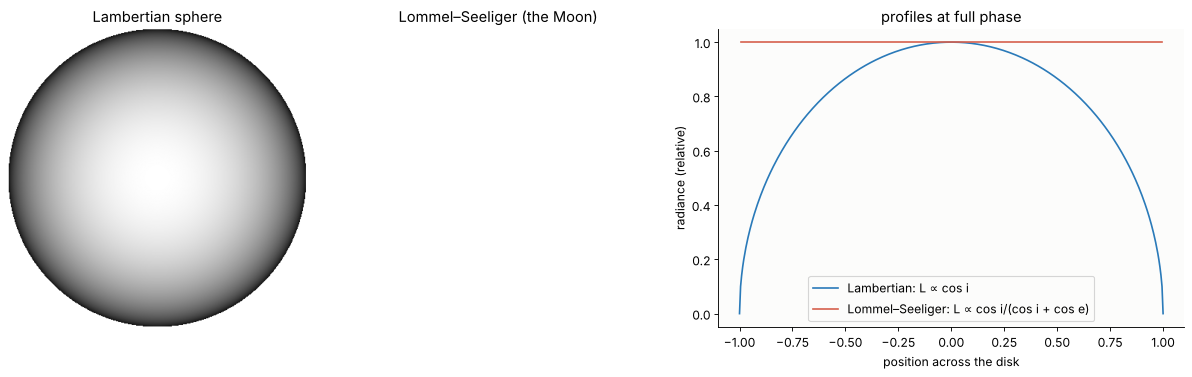

In [14]:
# the full Moon: a Lambertian sphere against the Lommel-Seeliger law
x = np.linspace(-1, 1, 401)
X, Y = np.meshgrid(x, x)
mu = np.sqrt(np.clip(1 - X**2 - Y**2, 0, None))   # cos(incidence) = cos(emission) at full phase
disk = X**2 + Y**2 < 1
L_lambert = np.where(disk, mu, np.nan)
L_ls = np.where(disk, 0.5, np.nan)                  # mu/(mu + mu)
fig, ax = plt.subplots(1, 3, figsize=(15, 4.6), layout="constrained", width_ratios=[1, 1, 1.4])
for a_, img, t in ((ax[0], L_lambert, "Lambertian sphere"), (ax[1], L_ls/0.5, "Lommel–Seeliger (the Moon)")):
    a_.imshow(img, cmap="gray", vmin=0, vmax=1, extent=(-1, 1, -1, 1))
    a_.set_title(t)
    a_.set_axis_off()
ax[2].plot(x, np.sqrt(np.clip(1 - x**2, 0, None)), color=BLUE, label="Lambertian: L ∝ cos i")
ax[2].plot(x, np.where(np.abs(x) < 1, 1.0, np.nan), color=RED, label="Lommel–Seeliger: L ∝ cos i/(cos i + cos e)")
ax[2].set_xlabel("position across the disk")
ax[2].set_ylabel("radiance (relative)")
ax[2].set_title("profiles at full phase")
ax[2].legend(loc="lower center")
plt.show()

Not every matte surface is Lambertian. At full Moon the Sun is behind the
observer, so at every point of the disk the angle of incidence $i$ equals
the angle of emission $e$. A Lambertian sphere would have the radiance
$\rho E\cos i/\pi$ there: bright in the middle, dark at the limb. The
Moon looks like a flat disk instead. Its dusty regolith is closer to the
Lommel–Seeliger law $L \propto \cos i/(\cos i + \cos e)$ of a layer of
weakly scattering particles, which is constant across the disk at full
phase. (The real Moon has more: at full phase it brightens further, the
opposition surge, because the shadows between the grains disappear.)

## 6. Photon quantities

Detectors count photons, and so does photosynthesis. For a sensor or a
plant, what matters is the photon flux, not the power. A photon of
wavelength $\lambda$ carries $hc/\lambda$, so a joule is
$2.8\times 10^{18}$ photons at 550 nm, more in the red and fewer in the
blue (`rad.photon_flux()`). Horticulture measures the photosynthetic
photon flux density (PPFD) in µmol m⁻² s⁻¹ over 400 to 700 nm.

In [15]:
N_A = 6.02214076e23
lp = np.linspace(400, 700, 3001)
print("photons per joule: 450 nm {:.3e}, 550 nm {:.3e}, 650 nm {:.3e}".format(
    *rad.photon_flux(1.0, np.array([450, 550, 650]))))
# sunlight as a 5772 K black body scaled to 1000 W/m² (all wavelengths)
S_sun = rad.planck_radiance(lp, T_sun)/rad.blackbody_radiance(T_sun)*1000.0  # W m^-2 nm^-1
ppfd = np.trapezoid(rad.photon_flux(S_sun, lp), lp)/N_A*1e6
E_v = rad.luminous_flux(lv, rad.planck_radiance(lv, T_sun)/rad.blackbody_radiance(T_sun)*1000.0)
print("1000 W/m² of 5772 K sunlight: PAR {:.0f} W/m², PPFD {:.0f} µmol m⁻² s⁻¹, illuminance {:.0f} klx".format(
    np.trapezoid(S_sun, lp), ppfd, E_v/1e3))
print("µmol/s per klm: sunlight {:.1f}".format(ppfd/(E_v/1e3)))
for share in (0.25, 0.15):
    S = white_led(lv, share)
    m = (lv >= 400) & (lv <= 700)
    ph = np.trapezoid(rad.photon_flux(S[m], lv[m]), lv[m])/N_A*1e6
    print("white LED, {:.0f} % blue: {:.1f} µmol/s per klm".format(100*share, ph/(rad.luminous_flux(lv, S)/1e3)))

photons per joule: 450 nm 2.265e+18, 550 nm 2.769e+18, 650 nm 3.272e+18
1000 W/m² of 5772 K sunlight: PAR 366 W/m², PPFD 1673 µmol m⁻² s⁻¹, illuminance 92 klx
µmol/s per klm: sunlight 18.2
white LED, 25 % blue: 12.5 µmol/s per klm
white LED, 15 % blue: 11.4 µmol/s per klm


Sunlight of 1000 W/m², modelled as a 5772 K black body, has 366 W/m² in
the band from 400 to 700 nm and a PPFD of about 1700 µmol m⁻² s⁻¹. Clear
sky noon sunlight is closer to 2000, because the atmosphere absorbs more
of the infrared than of the visible. Converting lux to PPFD depends on the
spectrum: 18 µmol s⁻¹ per klm for daylight, but only 11 to 13 for the
white LEDs, which put more of their power near the peak of $V(\lambda)$.
A lux meter is therefore a poor meter for plant lights. Notebook 106 (radiometry of images) uses
the same conversion to count the photons in a camera pixel.

## Summary

- **Four quantities:** flux (W, lm), intensity (W/sr, cd), irradiance and
  exitance (W/m², lx) and radiance (W m⁻² sr⁻¹, cd/m²), each with a
  spectral and a photon version. A Lambertian surface has $M = \pi L$ and
  $I = LA\cos\theta$. Its irradiance on a plane approaches the point
  source law $I_0\cos^4\theta/z^2$ only beyond a few source diameters.
- **Radiance is carried along rays:** the basic radiance $L/n^2$ is power
  per phase space volume. It stays constant in free space (1 % Monte Carlo
  noise from 0 to 15 mm), drops by the Fresnel transmittance at an
  interface, and the radiance in glass is $n^2T$ times that in air.
- **Black bodies:** Planck's law in absolute units, Wien and
  Stefan–Boltzmann; the Sun's 5772 K and angular radius give the solar
  constant of 1361 W/m², 1.8 × 10⁹ cd/m² and 125 klx.
- **Photometry:** $K_m = 683$ lm/W times $V(\lambda)$, from the candela at
  540 THz; night vision 1700 lm/W times $V'(\lambda)$. The analytic fits
  in `pyoptics.radiometry` are within 0.007 of the CIE tables (use the
  tables for calibration). Luminous efficacy of radiation: 16.5 lm/W for
  tungsten, at most 95 for any black body, 350 to 400 for white LEDs, 683
  for 555 nm only. Blue and red trade places at dusk (Purkinje), by a
  factor of 365 for 470 against 620 nm.
- **Exchange between surfaces:** view factors (closed forms, reciprocity,
  Monte Carlo), the integrating sphere with its multiplier
  $\rho/(1 - \rho(1 - f))$ (traced bounce by bounce: uniform after the
  first reflection), and the non-Lambertian full Moon.
- **Photons:** 2.8 × 10¹⁸ per joule at 550 nm; PPFD of daylight about
  18 µmol s⁻¹ per klm, of white LEDs 11 to 13.
- **Spectrometers:** the radiometry of the Jacquinot and Fellgett advantages is in notebook [111 (Fourier transform spectroscopy)](111_fourier_transform_spectroscopy.ipynb).

In [16]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 121 s


## References

- R. W. Boyd, *Radiometry and the Detection of Optical Radiation*, Wiley
  (1983).
- W. R. McCluney, *Introduction to Radiometry and Photometry*, 2nd ed.,
  Artech House (2014).
- J. M. Palmer and B. G. Grant, *The Art of Radiometry*, SPIE Press
  (2010).
- CIE 018:2019, *The Basis of Physical Photometry*, 3rd ed., and
  ISO 23539:2005/CIE S 010:2004, *Photometry: the CIE system of physical
  photometry* (the tables of $V(\lambda)$ and $V'(\lambda)$).
- BIPM, *The International System of Units (SI)*, 9th ed. (2019), on the
  definition of the candela.
- C. Wyman, P.-P. Sloan and P. Shirley, "Simple analytic approximations to
  the CIE XYZ color matching functions", J. Comput. Graph. Tech. 2(2),
  1–11 (2013).
- J. R. Howell, M. P. Mengüç, K. Daun and R. Siegel, *Thermal Radiation
  Heat Transfer*, 7th ed., CRC Press (2021), on view factors.
- Labsphere, *A Guide to Integrating Sphere Theory and Applications*
  (technical guide), on the sphere multiplier.
- B. Hapke, *Theory of Reflectance and Emittance Spectroscopy*, 2nd ed.,
  Cambridge University Press (2012), on the Lommel–Seeliger law and the
  opposition effect.
- G. Kopp and J. L. Lean, "A new, lower value of total solar irradiance:
  evidence and climate significance", Geophys. Res. Lett. 38, L01706
  (2011).